# 文本 00｜先让模型读一句评论（教师参考）

本页用于观察已完成的真实训练结果、图解与模型局限。学生提交的运行、补全和设计任务统一在[03](03_自主修改与挑战.ipynb)完成。


> **教师参考结果｜历史运行示例**　当前嵌入图来自2026-10-17本地CPU运行，原模型为 **GRU last**。配置与指标按原记录保留；这些不是学生一级普通RNN的新成绩，也不是学生二/三级实现。
>
> [完整原始快照](reference/20261017/00_情感分类体验.ipynb)（字节级保留，原配置和输出可查）。本页参考计算默认关闭，重新开启会产生新记录。
>
> 学生实际实验从[03 三级统一入口](03_自主修改与挑战.ipynb)开始：完整RNN调参 → 补全LSTM → 自建GRU；数据编码不熟悉时回看[01](01_文字如何变成序列.ipynb)。


> **课堂预览**　本页的图是 2026-10-17 的本地 CPU 运行快照，重新执行会更新；人工图解与训练结果已分别标明。只阅读可直接展开输出，实验时仍需从第一格执行。真实评论原文的打印未嵌入快照；有本地课程数据时运行对应格查看。

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt

# 支持从仓库根、03_rnn_lab、当前任务子目录启动，不依赖盘符或安装 rnn_lab。
LAB_DIR = next((candidate for base in (Path.cwd(), *Path.cwd().parents)
                for candidate in (base, base / "03_rnn_lab")
                if (candidate / "rnn_lab").is_dir()), None)
if LAB_DIR is None:
    raise FileNotFoundError("请从课程仓库、03_rnn_lab 或本任务目录启动 Notebook。")
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
DATA_DIR = LAB_DIR / "06_text_classification" / "data"
torch.set_num_threads(1)
from rnn_lab import configure_chinese_font, seed_everything
configure_chinese_font()
from rnn_lab.text_data import (load_text_data, build_vocab, encode_text,
    make_text_dataloaders, text_data_diagnostics, save_text_preprocessing,
    load_text_preprocessing)
from rnn_lab.text_engine import (TextExperimentConfig, run_text_experiment,
    predict_text, evaluate_text_final, export_text_experiments_csv, save_text_run)
from rnn_lab.text_plots import (plot_text_history, plot_text_confusion,
    plot_text_comparison, plot_text_states, text_examples)
print("实验室：", LAB_DIR, "；CPU 线程：", torch.get_num_threads())

实验室： <实验室目录> ；CPU 线程： 1


In [ ]:
# 教师需要重新演示时开启；不属于学生二/三级的实现。
RUN_TEACHER_REFERENCE = False


## 先看整条路径：不是把汉字直接丢进 RNN

沿箭头读图：文字先映射为整数编号，再查表得到向量。RNN 每读一个字，就把“本字的信息”和“上一步留下的状态”合成新的状态；读完后，分类头给出两类分数。

图中的 B/T/E/H 是不同轴的大小。先记住：**一个字会变成一组数，整句话经过一串状态更新后才得到一个预测。**这些状态是数值表示，并不等于人脑中的理解。

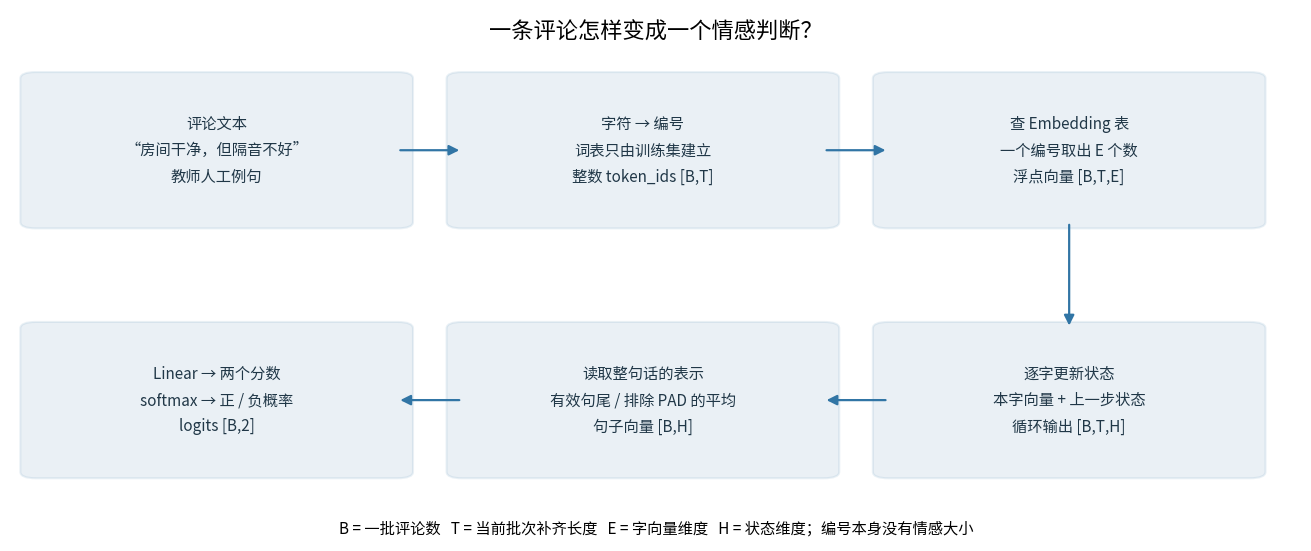

In [2]:
if RUN_TEACHER_REFERENCE:
    from rnn_lab.teaching_visuals import plot_text_pipeline
    import matplotlib.pyplot as plt
    
    fig = plot_text_pipeline()
    plt.show()
    plt.close(fig)
else:
    print("教师参考计算默认关闭；本页保留历史输出，完整原始快照见页首链接。")


## 先读真实评论与真实标签

下面来自课程离线包，不是教师编写的例句。标签映射由数据包读取，不凭评论里出现的某个词猜标签。长评论打印节选，完整原文保存在数据中。

预览不嵌入评论原文；准备好本地课程数据后执行下一格，就能查看前四条真实评论。仅阅读预览时，可先看后面的类别/长度图和人工探针。

In [3]:
if RUN_TEACHER_REFERENCE:
    data = load_text_data(DATA_DIR)
    print("数据版本：", data.version, "；类别：", dict(enumerate(data.class_names)))
    print("实际划分数量：", {split: len(records) for split, records in data.splits.items()})
    for record in data.splits["train"][:4]:
        print("\n样本：", record["id"], "；真实标签：", data.class_names[record["label"]])
        print(record["text"][:300])
else:
    print("教师参考计算默认关闭；本页保留历史输出，完整原始快照见页首链接。")


## 训练之前先读两张数据图

左图核对类别和划分；中图看训练评论有多长。虚线右边的评论超过 `max_length=100`，模型默认只读前 100 个字符，所以后半段可能完全没有进入模型。

右图说明三种划分的工作：训练集用于学参数和建词表，验证集用于比较方案，测试集留到方案固定后。**测试集的条数不是测试成绩。**先估计截断会影响多少评论，再看图中的实际比例。

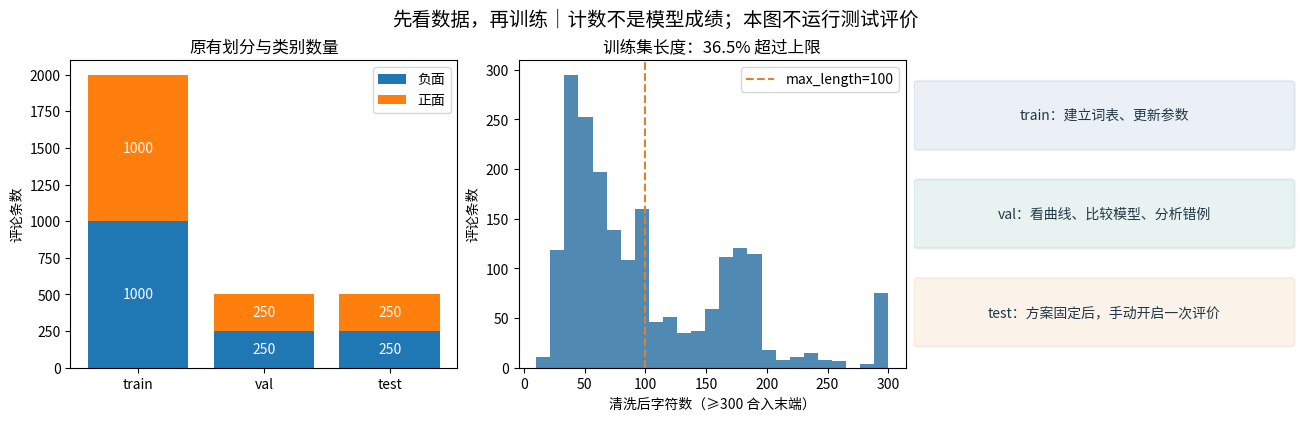

In [4]:
if RUN_TEACHER_REFERENCE:
    from rnn_lab.teaching_visuals import plot_data_roles
    import matplotlib.pyplot as plt
    
    fig = plot_data_roles(data, max_length=100)
    plt.show()
    plt.close(fig)
else:
    print("教师参考计算默认关闭；本页保留历史输出，完整原始快照见页首链接。")


## 一组小模型：Embedding → GRU → 有效句尾 → 分类

第一轮先保留配置。之后一次只改一个因素：`embedding_dim=E` 是每个字符查出的向量维度，`hidden_size=H` 是循环状态维度；字符 ID 本身不是连续语义坐标。Embedding 从随机值开始，与循环层和分类层一起训练。

默认单层、单向、零初始状态。循环层的 dropout 只发生在层间，单层时不生效。`max_length` 截断评论尾部，可能丢失转折和否定信息。概率是当前模型输出，不能称为经过校准的可信度。实际耗时由本次运行打印，不能预先保证。

In [5]:
if RUN_TEACHER_REFERENCE:
    config = TextExperimentConfig(
        name="体验｜GRU last", cell_type="gru", embedding_dim=32,
        hidden_size=32, num_layers=1, readout="last", max_length=100,
        batch_size=64, epochs=6, learning_rate=0.003, seed=42,
        device="cpu", dropout=0.0,
    )
    result = run_text_experiment(config, data, evaluate_test=False)
    print("词表大小（含 PAD/UNK）：", len(result["vocab"]))
    print("验证指标：", {k: result["val_metrics"][k] for k in ("loss", "accuracy")})
    print("实际参数量：", result["parameter_count"], "；训练秒数：", result["elapsed_seconds"])
    print("测试是否评价：", result["metrics"] is not None)
    print("截断、未知字与长度统计：", text_data_diagnostics(data, result["vocab"], config.max_length))
    RUN_DIR = save_text_run(result, LAB_DIR / "outputs" / "text" / "00_experience")
    print("本次目录：", RUN_DIR)
else:
    print("教师参考计算默认关闭；本页保留历史输出，完整原始快照见页首链接。")


词表大小（含 PAD/UNK）： 3081
验证指标： {'loss': 0.42181925582885743, 'accuracy': 0.8059999942779541}
实际参数量： 104994 ；训练秒数： 2.671407400004682
测试是否评价： False
截断、未知字与长度统计： {'train': {'samples': 2000, 'tokens': 146756, 'truncated_count': 731, 'truncated_fraction': 0.3655, 'unknown_count': 0, 'unknown_fraction': 0.0, 'all_unknown_count': 0, 'empty_count': 0, 'mean_original_length': 109.561}, 'val': {'samples': 500, 'tokens': 36428, 'truncated_count': 196, 'truncated_fraction': 0.392, 'unknown_count': 143, 'unknown_fraction': 0.0039255517733611505, 'all_unknown_count': 0, 'empty_count': 0, 'mean_original_length': 111.826}, 'test': {'samples': 500, 'tokens': 35742, 'truncated_count': 170, 'truncated_fraction': 0.34, 'unknown_count': 99, 'unknown_fraction': 0.0027698505959375523, 'all_unknown_count': 0, 'empty_count': 0, 'mean_original_length': 100.6}}
本次目录： <实验室目录>\outputs\text\00_experience\20261017_135227_768e7925


## 看曲线、混淆矩阵与具体样本

Loss 与 Accuracy 可能不完全同向。混淆矩阵只描述当前验证划分；再读正确和错误评论，判断否定、转折、长句或未知字是否值得进一步检查。单个错例只能提示现象，不能证明模型出错的唯一原因。

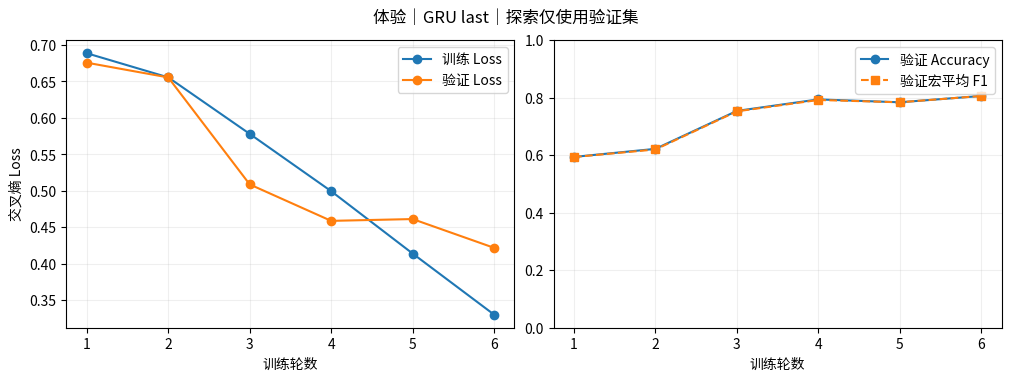

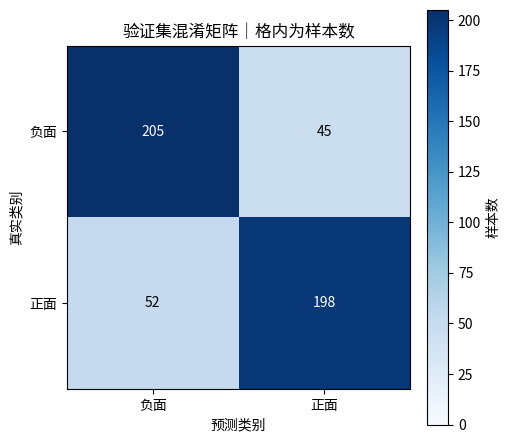

In [6]:
if RUN_TEACHER_REFERENCE:
    fig = plot_text_history(result)
    fig.savefig(RUN_DIR / "training_history.png", dpi=140, bbox_inches="tight")
    plt.show()
    fig = plot_text_confusion(result, split="val")
    fig.savefig(RUN_DIR / "validation_confusion.png", dpi=140, bbox_inches="tight")
    plt.show()
    print("验证集正确样本：")
    for example in text_examples(result, correct=True, limit=3):
        print(example)
    print("\n验证集错误样本（若当前没有错例会返回空列表）：")
    for example in text_examples(result, correct=False, limit=5):
        print(example)
else:
    print("教师参考计算默认关闭；本页保留历史输出，完整原始快照见页首链接。")


### 从图上读证据，而不是只读一个准确率

先用手指沿训练 Loss 曲线移动：下降说明模型正在更贴合训练标签。再比较验证 Loss；如果训练继续下降而验证回升，说明这种改善未必能迁移到未参与更新的评论。少量轮数的一次曲线不能证明已经得到最优模型。

混淆矩阵的纵轴是真实标签，横轴是预测标签：对角线是正确，其他格是错分。试着把一个非对角格读成完整句子：“真实负面的评论中，有多少被预测成正面？”随后从打印错例中找一条，检查它是否被截断、是否有未知字、是否含转折。

## 输入自己的评论

下面三句是**教师编写的额外演示**，不属于正式训练、验证或测试集。可以直接替换 `MY_REVIEW`。输出包含原文、实际编码长度、是否截断、未知字与预测概率。空文本或全 UNK 仍会产生数值输出，但不能据此作可靠情感判断；请查看返回的 empty、unknown_count 与 length 字段。

每次输入复用训练集词表和同一清理规则，未见字符映射到 UNK，不临时扩大词表。

In [7]:
if RUN_TEACHER_REFERENCE:
    MY_REVIEW = "房间很干净，不过隔音太差，整晚没有睡好。"
    for review in [MY_REVIEW, "服务很贴心，下次还会再来。", ""]:
        print(predict_text(result, review))
    print("预处理配置已随模型保存在：", RUN_DIR / "preprocessing.json")
else:
    print("教师参考计算默认关闭；本页保留历史输出，完整原始快照见页首链接。")


{'token_ids': [30, 23, 12, 498, 599, 2, 6, 53, 534, 187, 70, 103, 2, 380, 229, 27, 9, 536, 17, 4], 'length': 20, 'cleaned_text': '房间很干净,不过隔音太差,整晚没有睡好。', 'characters': ['房', '间', '很', '干', '净', ',', '不', '过', '隔', '音', '太', '差', ',', '整', '晚', '没', '有', '睡', '好', '。'], 'truncated': False, 'unknown_count': 0, 'empty': False, 'original_length': 20, 'text': '房间很干净，不过隔音太差，整晚没有睡好。', 'prediction': 0, 'predicted_class': '负面', 'probabilities': {'负面': 0.9475618600845337, '正面': 0.05243813991546631}}
{'token_ids': [51, 58, 12, 549, 102, 2, 56, 98, 18, 63, 147, 34, 4], 'length': 13, 'cleaned_text': '服务很贴心,下次还会再来。', 'characters': ['服', '务', '很', '贴', '心', ',', '下', '次', '还', '会', '再', '来', '。'], 'truncated': False, 'unknown_count': 0, 'empty': False, 'original_length': 13, 'text': '服务很贴心，下次还会再来。', 'prediction': 1, 'predicted_class': '正面', 'probabilities': {'负面': 0.22082841396331787, '正面': 0.7791715860366821}}
{'token_ids': [1], 'length': 1, 'cleaned_text': '', 'characters': ['<UNK>'], 'truncated': F

## 把自己的输入画出来：同一句话加上转折，会怎样？

下面五句是教师编写的额外探针，不属于正式训练、验证或测试。图中横条由当前训练模型实时计算。先比较前两句，再看否定句与最后一条较完整的评论：词语相似不保证整体意思相同，否定或转折也不保证模型一定处理正确。

每行检查有效长度、UNK 和截断标记。横条长只代表模型给该类的 softmax 值大，**不是经过校准的正确概率**。一次只改一个短语，再运行这一格即可，不必重训。

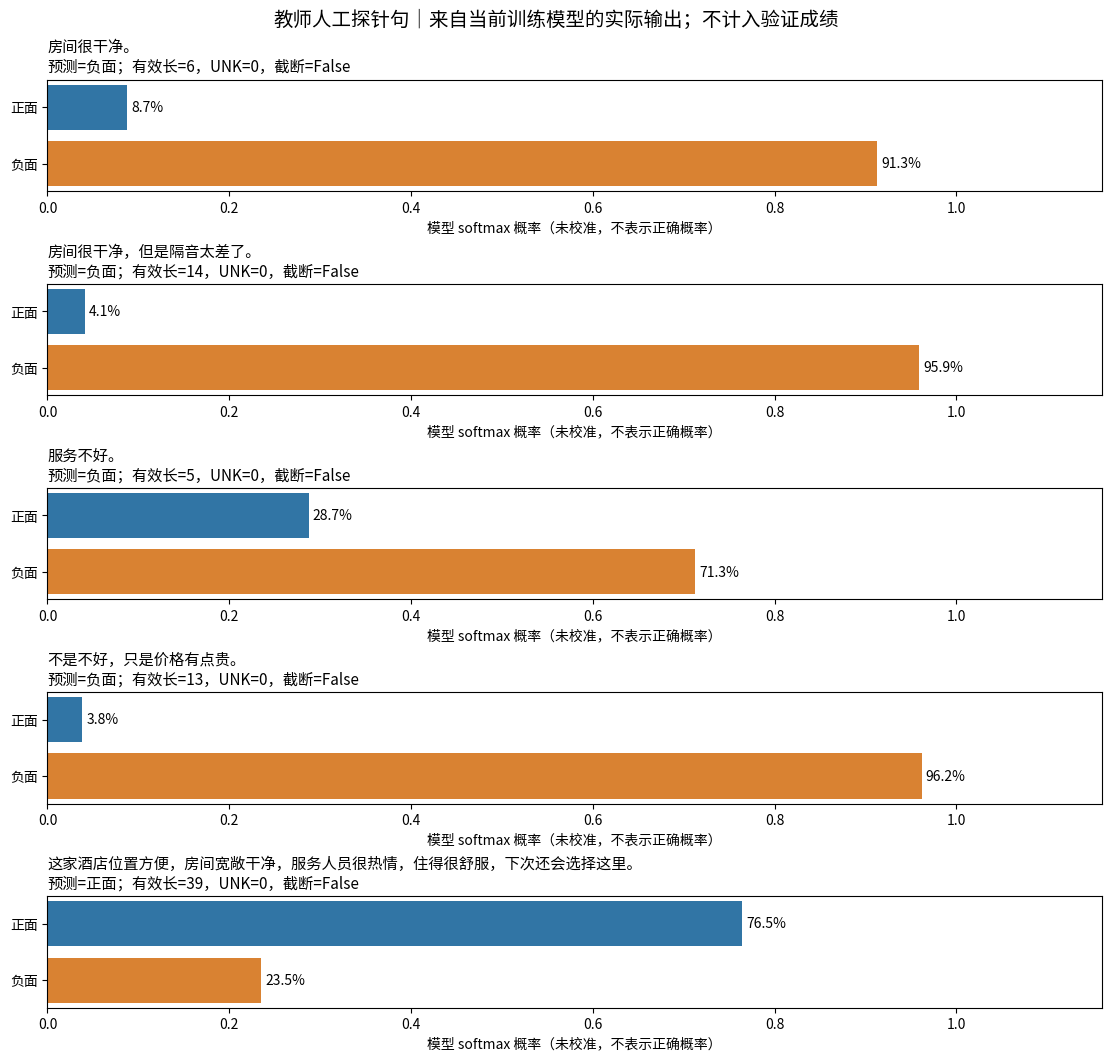

In [8]:
if RUN_TEACHER_REFERENCE:
    from rnn_lab.teaching_visuals import plot_review_predictions
    import matplotlib.pyplot as plt
    
    PROBE_REVIEWS = ["房间很干净。", "房间很干净，但是隔音太差了。", "服务不好。", "不是不好，只是价格有点贵。",
                     "这家酒店位置方便，房间宽敞干净，服务人员很热情，住得很舒服，下次还会选择这里。"]
    fig = plot_review_predictions(result, PROBE_REVIEWS)
    plt.show()
    plt.close(fig)
else:
    print("教师参考计算默认关闭；本页保留历史输出，完整原始快照见页首链接。")


### 把预测不符合直觉的地方留下来讨论

本次快照中，“房间很干净。”这样正面的短句也被判为负面。这是实际模型输出，不是示例的标准答案。先把人对句意的判断与模型概率分开，再检查编码是否正常。长度、训练评论的表达方式、局部词语或当前参数都可能有关；只看这一个例子不能确定原因。

**先预测—改一项—验证—解释：**先写出你预计“不过/但是”会怎样改变判断，再只改自己的评论，不重新训练。模型是否始终按预期变化？引用概率和编码信息说明。接下来 [01](01_文字如何变成序列.ipynb) 解释文字怎样进入模型。

## 保存与结束

本页输出写入带运行标识的新目录，保留旧记录。先保存 Notebook，再按需运行下一格关闭图片。本页不自动关闭内核；不要为了重新看图反复训练。共享服务器每次只运行一个训练任务。

In [9]:
if RUN_TEACHER_REFERENCE:
    # 需要重新实验时建议重启内核，从头运行；本格仅关闭图片。
    plt.close("all")
else:
    print("教师参考计算默认关闭；本页保留历史输出，完整原始快照见页首链接。")
